# Assignment 3 - Erling

## Imports

In [ ]:
import sys
from pathlib import Path

# Imports works reagardless of where the module is run from, as long as the working directory is either the repo root or notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# Java and Spark envvironment variables
import os

import certifi
import matplotlib.pyplot as plt
import pandas as pd
from cassandra.cluster import Cluster
from dotenv import load_dotenv
from pymongo import MongoClient
import numpy as np

os.environ["JAVA_HOME"] = "/Library/Java/JavaVirtualMachines/microsoft-17.jdk/Contents/Home"
os.environ["PYSPARK_PYTHON"] = "python"
os.environ["PYSPARK_DRIVER_PYTHON"] = "python"

from pyspark.sql import SparkSession
from pyspark.sql.functions import avg, col

from modules.weather_utils import fetch_weather_for_region, sample_points_per_region
from modules.analysis_utils import (
    plot_precipitation_outliers,
    plot_temperature_anomalies,
    plot_fill_degree_stl,
    plot_fill_degree_spectrogram,
)
from modules.data_utils import load_data, filter_area_type

load_dotenv()

2026-11-10 10:06:39.303 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


True

## Sample 1000 locations per region from the NVE shapefiles

Start by sampling 1000 random points from each electrical region. This points will later be used to extract the weather data with API connection to open-meto. 

In [2]:
# paths to shapefiles for the two different region definitions
BUDOMRADER_SHP = PROJECT_ROOT / "data/shapefiles/budomrader/Budområder.shp"
NVE_REGIONER_SHP = PROJECT_ROOT / "data/shapefiles/nve_regioner/NVE_Region.shp"

# Number of points to sample, test with 10 points to test
N_POINTS = 1000

# The sample fonction comes from modules/weather_utils.py
budomrader_points = sample_points_per_region(BUDOMRADER_SHP, "budomr", n_points=N_POINTS, seed=0)
budomrader_points["region"] = budomrader_points["region"].str.replace(" ", "")  # "NO 3" -> "NO3"

nve_region_points = sample_points_per_region(NVE_REGIONER_SHP, "REGION", n_points=N_POINTS, seed=0)

# Combine the two sets of points into a single DataFrame for later use
all_points = pd.concat([budomrader_points, nve_region_points], ignore_index=True)
print(all_points["region"].value_counts())
all_points.head()

region
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
RV     1000
RM     1000
RN     1000
RØ     1000
RS     1000
Name: count, dtype: int64


,region,lat,lon
0,NO1,61.302141,12.446467
1,NO1,62.407025,10.957413
2,NO1,60.251611,11.555043
3,NO1,60.171082,10.650910
4,NO1,60.027175,11.975108


### Download hourly ERA5 weather for NO3, 2024

`fetch_weather_for_region()` takes a region identifier and a time interval, looks up that region's 1000 sampled points in `all_points`, and downloads hourly ERA5 temperature, precipitation and snowfall for all of them from open-meteo. This is a lot of data. 

In [ ]:
# Fetch weather data for all points in NO3 the year 2024 by calling the fetch_weather_for_region function from modules/weather_utils.py
# This function will return a DataFrame with the weather data for all points in the specified region and time period.
# This means with 1000 points, 24 hours per day, 365 days per year, we will have 1000 * 24 * 365 = 8,784,000 rows of data
# and 8 columns of data (region, point_id, lat, lon, time, temperature, precipitation, snowfall)
raw_weather = fetch_weather_for_region("NO3", all_points, "2024-01-01", "2024-12-31")
print(raw_weather.shape)
raw_weather.head()

(8784000, 8)


,region,point_id,lon,lat,timestamp,temperature_2m,precipitation,snowfall
0,NO3,0,10.032239,63.4671,2024-01-01T00:00,-2.3,0.0,0.0
1,NO3,0,10.032239,63.4671,2024-01-01T01:00,-2.4,0.0,0.0
2,NO3,0,10.032239,63.4671,2024-01-01T02:00,-2.2,0.0,0.0
3,NO3,0,10.032239,63.4671,2024-01-01T03:00,-2.0,0.0,0.0
4,NO3,0,10.032239,63.4671,2024-01-01T04:00,-1.9,0.0,0.0


### Average precipitation and temperature across NO3's sampled points

In [29]:
# Takes every hour and calculates the average temperature, precipitation and snowfall for all points in NO3 for that hour. 
# This will result in a 1000 points * 24 hours * 365 days = 8,784 rows of data, with 3 columns of data (temperature, precipitation, snowfall)
hourly_avg = raw_weather.groupby("timestamp")[["temperature_2m", "precipitation", "snowfall"]].mean()
hourly_avg.index = pd.to_datetime(hourly_avg.index)
hourly_avg = hourly_avg.sort_index()

print(hourly_avg.shape)
hourly_avg.head()

(8784, 3)


,temperature_2m,precipitation,snowfall
timestamp,,,
2024-01-01 00:00:00,-3.9682,0.0031,0.00161
2024-01-01 01:00:00,-4.0985,0.0023,0.00161
2024-01-01 02:00:00,-4.0669,0.0023,0.00161
2024-01-01 03:00:00,-4.0866,0.0023,0.00161
2024-01-01 04:00:00,-4.0247,0.0022,0.00154


## Outliers and anomalies

### Plot the average precipitation as a function of time

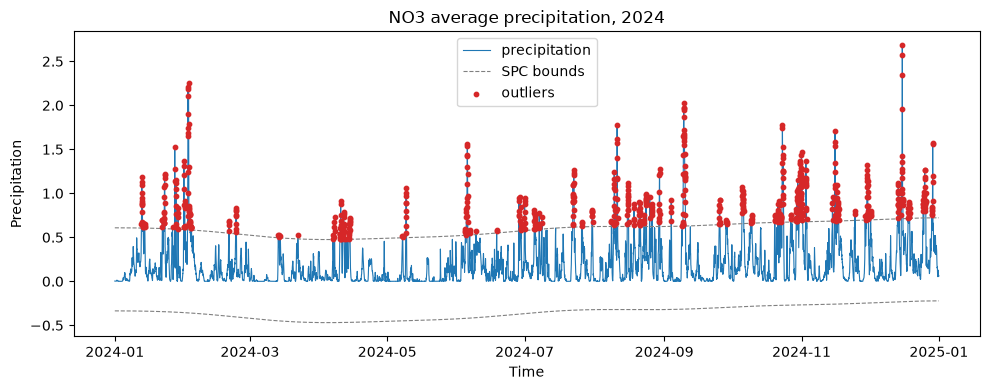

685 outlier hours flagged out of 8784


,timestamp,value,satv
0,2024-01-12 20:00:00,0.6535,0.440766
1,2024-01-12 21:00:00,0.8679,0.655184
2,2024-01-12 22:00:00,1.0027,0.790002
3,2024-01-12 23:00:00,1.1305,0.917819
4,2024-01-13 00:00:00,1.1897,0.977037


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
# plot_precipitation_outliers is a function from modules/analysis_utils.py that takes a pandas Series of precipitation values and plots the outliers. 
# It returns the matplotlib axis and a DataFrame of the outlier values.
ax, precip_outliers = plot_precipitation_outliers(hourly_avg["precipitation"], ax=ax)
# plot_precipitation_outliers uses a DCT high-pass filter to split the series into a smooth seasonal trend and a high-frequency residual. 
# Robust statistics (median and a normal-consistent MAD) computed over the SATV give constant control limits in residual space; 
# adding the seasonal trend back turns that into a boundary CURVE in the original units, which is what actually gets plotted 
plt.title("NO3 average precipitation, 2024")
plt.tight_layout()
plt.show()

print(f"{len(precip_outliers)} outlier hours flagged out of {len(hourly_avg)}")
precip_outliers.head()


### Plot the average temperature as a function of time with the anomalous hours flagged. 

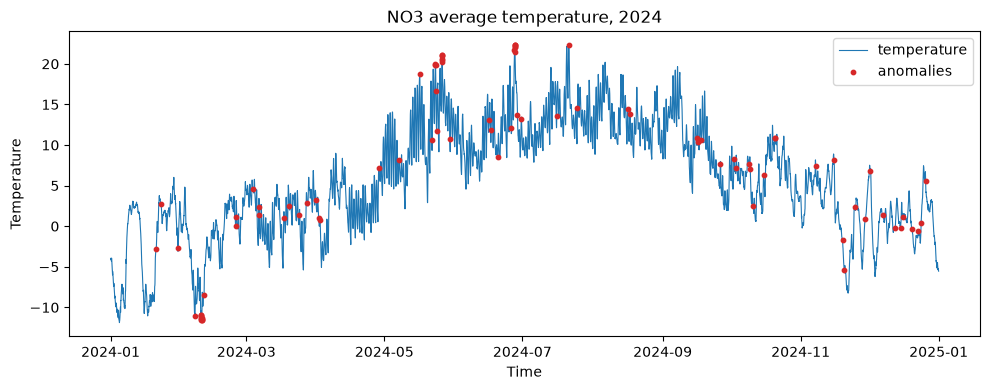

88 anomalous hours flagged out of 8784


,timestamp,value,lof_score
10,2024-02-10 05:00:00,-11.5915,3.048475
11,2024-02-10 06:00:00,-11.5044,2.865611
9,2024-02-10 04:00:00,-11.4988,2.836114
8,2024-02-10 03:00:00,-11.4802,2.788803
12,2024-02-10 07:00:00,-11.4226,2.706127


In [30]:
# The anomalous hours are defined as those where the temperature is more than 3 standard deviations away from the mean temperature for that hour of the year.
# Anomalurs are different from utliers, as the outliers is defined after a high-pass filter is applied to the series, while the anomalous hours are defined based on the raw temperature values.
fig, ax = plt.subplots(figsize=(10, 4))
ax, temp_anomalies = plot_temperature_anomalies(hourly_avg["temperature_2m"], ax=ax)
plt.title("NO3 average temperature, 2024")
plt.tight_layout()
plt.show()

print(f"{len(temp_anomalies)} anomalous hours flagged out of {len(hourly_avg)}")
temp_anomalies.head()


## Seasonal-Trend decomposition using LOESS (STL)

### Fill degree, NO3

In [ ]:
# load the magasin data from the magasin API, 
# filter the data to only include areas of type "EL", and then select the fill degree for area number 3.
magasin = load_data()
el_areas = filter_area_type(magasin, "EL")
fill_degree_no3 = el_areas.loc[el_areas["area_number"] == 3, "fill_degree"].sort_index()

print(fill_degree_no3.shape)
fill_degree_no3.head()


2026-11-10 10:06:44.254 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-10 10:06:44.256 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


(1661,)


dato_Id
1995-01-08    0.602376
1995-01-15    0.569943
1995-01-22    0.542203
1995-01-29    0.508148
1995-02-05    0.473883
Name: fill_degree, dtype: float64

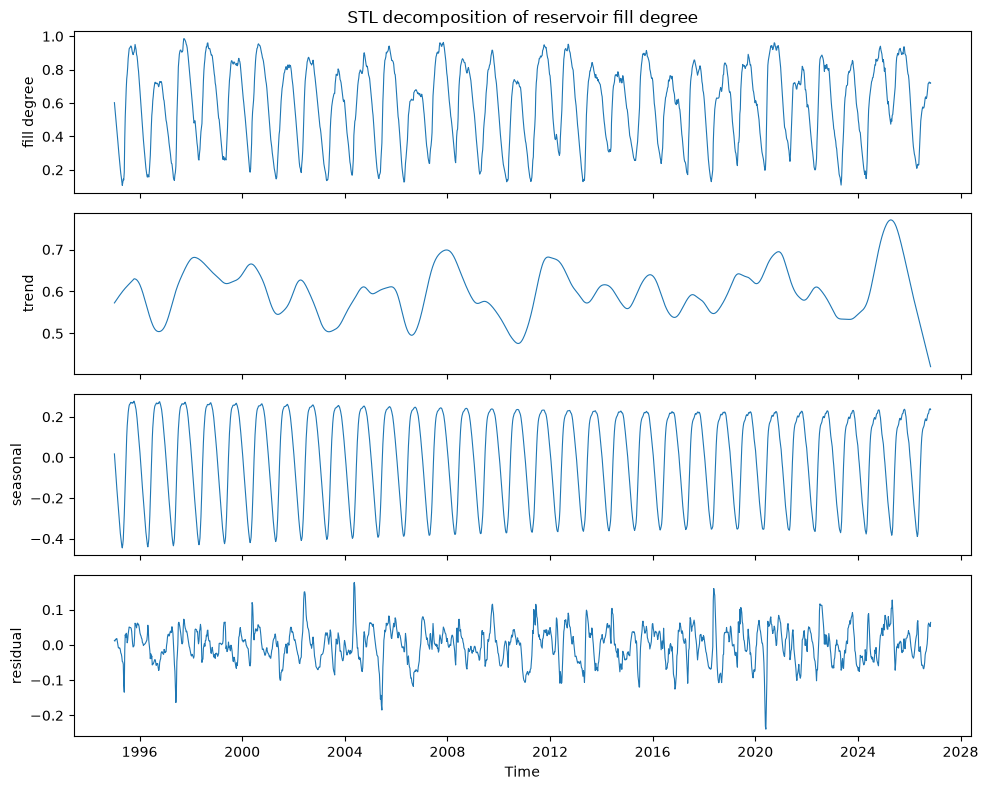

In [26]:
# Do a STL decomposition of the NO3 reservoir fill degree time series and plot the results.
axes, stl_result = plot_fill_degree_stl(fill_degree_no3)
plt.show()


## Spectrogram

### Fill degree, NO3

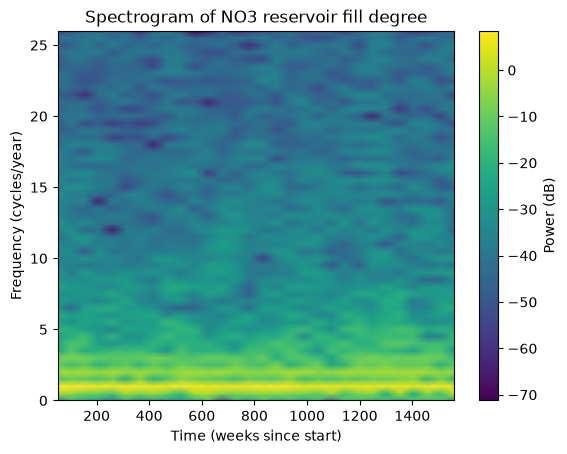

In [27]:
ax, (freqs, times, Sxx) = plot_fill_degree_spectrogram(fill_degree_no3)
plt.title("Spectrogram of NO3 reservoir fill degree")
plt.show()


### Write the raw readings into Cassandra via Spark

The raw weather readings for NO3 add up to almost 8.8 million rows (1000 sampled points × 8784 hours), which is too much to read in and re-aggregate with pandas every time the Streamlit app reruns. So instead I write the raw per-point readings into Cassandra, which is built for exactly this kind of time-series data, and use Spark to read them back out and do the heavy lifting - grouping by timestamp and averaging across all 1000 points to get a single hourly series for NO3. That aggregated result is small (one row per hour, 8784 rows total), so I store it in MongoDB, and that’s what the Streamlit app actually reads from.

In [14]:
KEYSPACE = "weather"
TABLE = "era5_hourly"

# Create the keyspace/table directly over the Cassandra driver (one-off, not something Spark needs to do)
cluster = Cluster(["127.0.0.1"])
cassandra_session = cluster.connect()
cassandra_session.execute(f"""
    CREATE KEYSPACE IF NOT EXISTS {KEYSPACE}
    WITH replication = {{'class': 'SimpleStrategy', 'replication_factor': 1}}
""")
cassandra_session.execute(f"""
    CREATE TABLE IF NOT EXISTS {KEYSPACE}.{TABLE} (
        region text,
        point_id int,
        timestamp timestamp,
        lon double,
        lat double,
        temperature_2m double,
        precipitation double,
        snowfall double,
        PRIMARY KEY ((region, point_id), timestamp)
    )
""")
cluster.shutdown()
print("Cassandra keyspace/table ready.")

spark = (
    SparkSession.builder.appName("WeatherCassandraApp")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    # Without this, converting an 8-million-row pandas DataFrame to Spark goes
    # row-by-row through the Python<->JVM bridge - slow enough on a dataset
    # this size that it can look indistinguishable from hung. Arrow batches
    # that conversion instead of doing it one row at a time.
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    # open-meteo's timestamps are UTC (requested with timezone="UTC"), but
    # Arrow's pandas->Spark conversion otherwise interprets naive timestamps
    # using the session's LOCAL timezone - which breaks outright for
    # 2024-03-31 02:00, a UTC instant that falls inside the hour Norway's own
    # clocks skip that day for daylight savings (it genuinely doesn't exist
    # as Oslo local time). Pinning the session timezone to UTC avoids that
    # local-time interpretation entirely. This is a runtime SQL config, so it
    # takes effect even when (per the "using an existing Spark session"
    # warning) this reuses the test cell's already-running session.
    .config("spark.sql.session.timeZone", "UTC")
    # Local mode defaults to a 1GB driver heap, which is nowhere near enough
    # to hold the groupBy/shuffle over 8.78M rows in memory (this is a JVM
    # startup setting - it has to be here, at session creation, not set
    # later on an already-running session).
    .config("spark.driver.memory", "6g")
    .getOrCreate()
)
spark.conf.set("spark.sql.session.timeZone", "UTC")  # belt-and-braces, in case the config above didn't apply to a reused session
print("Spark session ready.")  # if this doesn't print quickly, the hang is in session/jar setup, not the write

raw_weather_spark = raw_weather.copy()
# utc=True makes the UTC-ness explicit on the pandas side too, rather than
# leaving these as naive timestamps for Spark/Arrow to guess a timezone for.
raw_weather_spark["timestamp"] = pd.to_datetime(raw_weather_spark["timestamp"], utc=True)

# createDataFrame's pandas->Arrow fast path has hit two separate incompatibilities
# on this dataset (a DST edge case, then a "Cannot convert ChunkedArray to Array"
# bug) and silently falls back to the slow row-by-row conversion either way - so
# rather than keep fighting that specific path, skip it entirely: write the pandas
# DataFrame straight to a local Parquet file and have Spark read ITS OWN Parquet
# back in, a completely separate, far more battle-tested code path that never
# touches the pandas<->JVM conversion at all.
parquet_path = str(PROJECT_ROOT / "data" / "cache" / "raw_weather_no3.parquet")
raw_weather_spark.to_parquet(parquet_path, index=False)
sdf = spark.read.parquet(parquet_path)
print("Spark DataFrame created (", sdf.count(), "rows ) - starting Cassandra write...")  # forces evaluation here, before the write, so we know which step is slow

(
    sdf.write.format("org.apache.spark.sql.cassandra")
    .options(table=TABLE, keyspace=KEYSPACE)
    .mode("append")
    .save()
)
print("Wrote", sdf.count(), "rows to Cassandra.")

Cassandra keyspace/table ready.


26/11/10 10:06:46 WARN Utils: Your hostname, MacBook-Pro-od-Erling.local resolves to a loopback address: 127.0.0.1; using 172.20.10.5 instead (on interface en0)
26/11/10 10:06:46 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/erlinghamilmysen/.ivy2/cache
The jars for the packages stored in: /Users/erlinghamilmysen/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-ceea324f-e404-4884-ac0f-db6c35455d67;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central


:: loading settings :: url = jar:file:/Users/erlinghamilmysen/Documents/Skole/H%c3%b8st27/erlinghm-ind320/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassandra#java-driver-query-builder;4.18.1 in central
	found org.apache.commons#commons-lang3;3.10 in central
	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found org.scala-lang#scala-reflect;2.12.19 in central
:: resolution report :: resolve 209ms :: artifacts dl 6ms
	:: modules in use:
	com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal

Spark session ready.
Spark DataFrame created ( 8784000 rows ) - starting Cassandra write...


Wrote 8784000 rows to Cassandra.


### Read back from Cassandra via Spark and aggregate to an hourly regional average

The DCT/SPC and LOF analyses later work on a single average precipitation/temperature series per region, not 1000 separate point series - this averages across all of NO3's sampled points for each hour.

In [15]:
weather_spark = (
    spark.read.format("org.apache.spark.sql.cassandra")
    .options(table=TABLE, keyspace=KEYSPACE)
    .load()
    .filter(col("region") == "NO3")
)

hourly_avg = (
    weather_spark.groupBy("region", "timestamp")
    .agg(
        avg("temperature_2m").alias("temperature_2m_avg"),
        avg("precipitation").alias("precipitation_avg"),
        avg("snowfall").alias("snowfall_avg"),
    )
    .orderBy("timestamp")
)

weather_hourly_avg = hourly_avg.toPandas()
spark.stop()

print(weather_hourly_avg.shape)
weather_hourly_avg.head()

(8785, 5)


,region,timestamp,temperature_2m_avg,precipitation_avg,snowfall_avg
0,NO3,2023-12-31 23:00:00,-2.3000,0.0000,0.00000
1,NO3,2024-01-01 00:00:00,-3.9682,0.0031,0.00161
2,NO3,2024-01-01 01:00:00,-4.0985,0.0023,0.00161
3,NO3,2024-01-01 02:00:00,-4.0669,0.0023,0.00161
4,NO3,2024-01-01 03:00:00,-4.0866,0.0023,0.00161


### Store the regional hourly average in MongoDB

Same pattern as the cross-border daily totals in Part 2 - this is the collection a Streamlit page would read from directly.

In [18]:
from pymongo import UpdateOne

uri = os.environ["MONGODB_URI"]
mongo_client = MongoClient(uri, tlsCAFile=certifi.where())
db = mongo_client["ind320"]
weather_collection = db["weather_hourly_avg"]

# One update_one() call per row means one network round-trip to MongoDB Atlas
# per row - ~8784 of them here, which is what made this take several minutes.
# bulk_write() batches them all into (effectively) a single round-trip instead.
operations = [
    UpdateOne(
        {"region": row["region"], "timestamp": row["timestamp"].isoformat()},
        {"$set": {
            "temperature_2m_avg": float(row["temperature_2m_avg"]),
            "precipitation_avg": float(row["precipitation_avg"]),
            "snowfall_avg": float(row["snowfall_avg"]),
        }},
        upsert=True,
    )
    for _, row in weather_hourly_avg.iterrows()
]
result = weather_collection.bulk_write(operations)
print(f"Upserted {result.upserted_count + result.modified_count} hourly documents into MongoDB.")

Upserted 6014 hourly documents into MongoDB.


### Work log

For this assignment, Part 3, I started off with finding the right shapefiles on the Atlas site, and familiarizing myself with the open-meteo API.

I then went on with this Jupyter Notebook, and the data exploration part. For this assignment, most of the code is built in /modules, rather than in the Jupyter notebook.

I started off by making the part that aggregates 1000 random points from the different zones. This code is under /modules. Then I had some issues with the weather data. I wasn't able to talk to the API service correctly, resulting in reaching the API's hourly limit a few times, and eventually I hit the API's daily call limit and couldn't request any more. That got solved.

I then went on with the outliers and anomalies, which went pretty painlessly, ending up with a good structure where I pretty much follow the recipe in the assignment text. The spectrogram part I think is a new concept for me, so I spent some time familiarizing myself with that.

For the Streamlit app, I restructured it around a shared area selector (EL/NO/VASS + area number) that persists across pages via st.session_state, added a dedicated page for the weather download control since fetching from open-meteo takes a while and shouldn't block the other pages, added two new tabbed pages (st.tabs()) — one for STL + Spectrogram, one for the SPC outlier detection + LOF anomaly detection, each with its own parameter widgets and stats — and reordered the pages into a more logical grouping.

The bigger piece of work was getting the weather data into the Cassandra → Spark → MongoDB pipeline I'd set up in Part 2, which I'd left unused for the weather data. The point of doing this wasn't just to reuse the infrastructure — re-reading and reprocessing 1000 points × 8784 hours from CSV on every Streamlit rerun is genuinely too slow, so storing the hourly NO3 average in MongoDB is meant to fix that.
### AI Usage

I used AI a lot this part, both as a stats tutor and as a debugging partner. For STL and the spectrogram, I used it to understand what the parameters actually control before wiring them into functions, and to help organize the code. When running into problems and getting lost, I used AI to help me get back on track again.

For the Streamlit restructure, I talked through the page layout and shared-state approach with it before writing the pages.

The Cassandra/Spark/MongoDB pipeline was where I leaned on it the most. I pasted real tracebacks as they happened — the DST timestamp error, the PyArrow error, the OutOfMemoryError, the ConnectionRefusedError after a kernel restart — and had it diagnose each one from the actual error rather than suggest random things to try, since this was all new to me and the runs took a long time, so guessing wrong was expensive. It also caught the weather-cache collision bug and the open-meteo rate-limit gap, and rewrote a slow per-row MongoDB update loop into a much faster batched upsert. When MongoDB ended up with one extra document, I asked it to help track down the cause; given time pressure before the deadline, we agreed the pragmatic fix (deleting the one stray document) was good enough rather than re-running the whole pipeline to find the exact root cause.
